# **Problem Statement Selection**



# Brain Tumor Detection and Classification Using ANN

## Project Title
**Brain Tumor Detection and Classification Using Artificial Neural Network (ANN)**


## Problem Statement
Brain tumors are difficult to detect manually from MRI images and require expert analysis.
The objective of this project is to build an Artificial Neural Network (ANN) model that can
automatically analyze brain MRI images and classify them into different tumor categories.


## Business Objective
- To develop an AI-based system for automatic brain tumor detection.
- To assist doctors and radiologists in faster diagnosis.
- To reduce manual analysis effort and improve decision-making.
- To support early detection of brain tumor types.


## Expected Output
The trained ANN model takes a brain MRI image as input and predicts the tumor category.

**Input:** Brain MRI Image

**Output:** Predicted Tumor Class

Example:
- Glioma Tumor
- Meningioma Tumor
- Pituitary Tumor
- No Tumor


## Target Variable
The target variable is the **Brain Tumor Class** that the model predicts.

Classes:
- 0 → Glioma
- 1 → Meningioma
- 2 → Pituitary
- 3 → No Tumor


## Input Features
The input features are numerical representations extracted from MRI images.

Features include:
- MRI image pixel values
- HOG (Histogram of Oriented Gradients) features
- Image intensity values
- Texture and shape information

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.feature import hog
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#Dataset Import

In [ ]:
import zipfile
import os

# Path to your ZIP file in Google Drive
zip_path = "/content/drive/MyDrive/Deep Learning/Brain tumor MRI Detection Project /Dataset/archive.zip"

# Folder where the files will be extracted
extract_path = "/content/drive/MyDrive/Deep Learning/Brain tumor MRI Detection Project /Extracted_Files"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP file extracted successfully!")
print("Files saved to:", extract_path)

ZIP file extracted successfully!
Files saved to: /content/drive/MyDrive/Deep Learning/Brain tumor MRI Detection Project /Extracted_Files


In [3]:
train_path = "/content/drive/MyDrive/Deep Learning/Brain tumor MRI Detection Project /Extracted_Files/Training"
test_path = "/content/drive/MyDrive/Deep Learning/Brain tumor MRI Detection Project /Extracted_Files/Testing"

# Exploratary Data Analysis.

**Verify the classes in train and test data**

---



In [4]:
def classes(path):
  classes = os.listdir(path)

  print("\nclasses:", classes)
  print('Number of classes : ', len(classes))

classes(train_path)
classes(test_path)


classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes :  4

classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes :  4


**Display the number of images in each class in train and test data**

In [5]:
def count(path):
  # Count images in each class
  total = 0
  for folder in os.listdir(path):
    folder_path = os.path.join(path, folder)
    count = len(os.listdir(folder_path))
    print(f'{folder} : {count}')
    total += count

  print(f'\nTotal Training Images : {total}\n\n')

count(train_path)
count(test_path)

glioma : 1400
meningioma : 1400
notumor : 1400
pituitary : 1400

Total Training Images : 5600


glioma : 400
meningioma : 400
notumor : 400
pituitary : 400

Total Training Images : 1600




**Displaying image from each class**

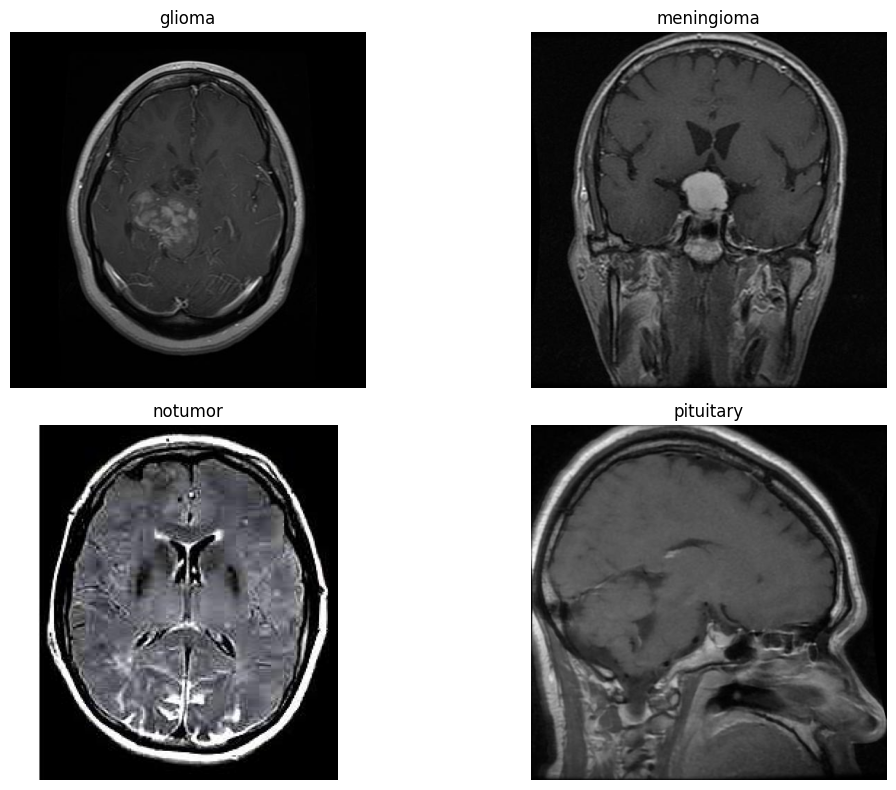

In [9]:
plt.figure(figsize=(12,8))
for i, folder in enumerate(os.listdir(train_path)):
  img_name = os.listdir(os.path.join(train_path, folder))[0]
  img_path = os.path.join(train_path, folder, img_name)
  img = cv2.imread(img_path)
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  plt.subplot(2,2,i+1)
  plt.imshow(img)
  plt.title(folder)
  plt.axis('off')

plt.tight_layout()
plt.show()

**Shape of image**


In [10]:
print('Image Shape: ',img.shape)

Image Shape:  (512, 512, 3)


**Checking Brain Tumor class Distrinbution in train and test data:**

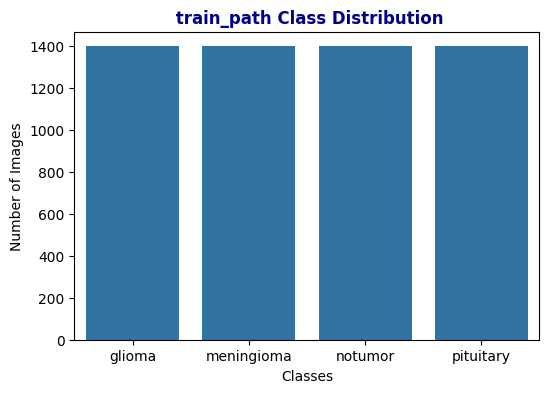

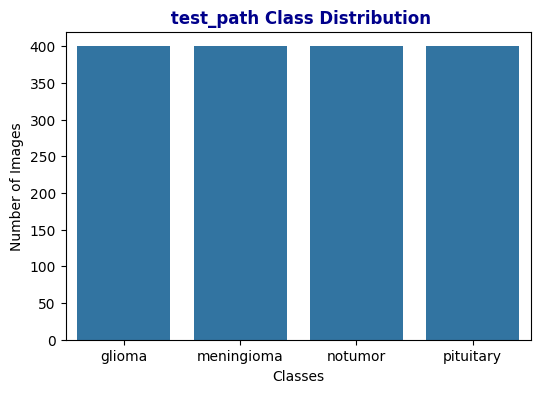

In [11]:
for i,path in zip(("train_path","test_path"),[train_path,test_path]):
  classes = os.listdir(path)
  class_counts = [len(os.listdir(os.path.join(path,folder))) for folder in classes]
  plt.figure(figsize=(6,4))
  sns.barplot(x=classes, y= class_counts)
  plt.title(f' {i} Class Distribution',fontsize = 12, fontweight ='bold', color = 'darkblue')
  plt.xlabel('Classes')
  plt.ylabel('Number of Images')
  plt.show()
  print()



**Overall Insights:**

1. This Dataset contains 2 folder
* Train data
* Test data

2. In Train data contains 4 Difflerent classes is

* glioma : 1400
* meningioma : 1400
* notumor : 1400
* pituitary : 1400

 Each class contains 1400 images and total images are 5600

 This is balanced dataset all classes are equally distributed.


3. In Test data contains 4 Difflerent classes is

* glioma : 400
* meningioma : 400
* notumor : 400
* pituitary : 400

 Each class contains 1400 images and total images are 1600

 This is balanced dataset all classes are equally distributed.

# Preprocessing

In [12]:
def preprocessing(path):

  img_size = 64
  X = []
  y = []
  classes = os.listdir(path)
  for folder in classes:
    folder_path = os.path.join(path, folder)
    for img_name in os.listdir(folder_path):
      img_path = os.path.join(folder_path,img_name)
      img = cv2.imread(img_path)
      img = cv2.resize(img,(img_size,img_size))
      gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
      gray = gray / 225.0
      features = hog(
                      gray,
                      orientations =9,
                      pixels_per_cell = (8,8),
                      cells_per_block= (2,2),
                      block_norm="L2-Hys"
                    )
      X.append(features)
      y.append(folder)

  # Checking data type of input and target data
  print('\n\nInput Data type : ',type(X))
  print('Target data type: ', type(y))


  # Convert list to Numpy Arrays
  X = np.array(X)
  y = np.array(y)
  print('Input Data Type :', type(X))
  print('Input Data Shape :', X.shape)

  print('\nTarget data type: ', type(y))
  print('Target Data Shape :', y.shape)



  # Labele Encoding on target data
  le = LabelEncoder()
  y = le.fit_transform(y)
  print(le.classes_)

  return X, y

In [21]:
# Preprocessing on train data
X_train, y_train = preprocessing(train_path)
print('\nPreprocessing Completed..')
print('\nShape of X_train :',X_train.shape)
print('Shape of y_train :',y_train.shape)



Input Data type :  <class 'list'>
Target data type:  <class 'list'>
Input Data Type : <class 'numpy.ndarray'>
Input Data Shape : (5600, 1764)

Target data type:  <class 'numpy.ndarray'>
Target Data Shape : (5600,)
['glioma' 'meningioma' 'notumor' 'pituitary']

Preprocessing Completed..

Shape of X_train : (5600, 1764)
Shape of y_train : (5600,)


In [22]:
# Preprocessing on test data
X_test, y_test = preprocessing(test_path)
print('\nPreprocessing Completed..')
print('\nShape of X_test :',X_test.shape)
print('Shape of y_test :',y_test.shape)



Input Data type :  <class 'list'>
Target data type:  <class 'list'>
Input Data Type : <class 'numpy.ndarray'>
Input Data Shape : (1600, 1764)

Target data type:  <class 'numpy.ndarray'>
Target Data Shape : (1600,)
['glioma' 'meningioma' 'notumor' 'pituitary']

Preprocessing Completed..

Shape of X_test : (1600, 1764)
Shape of y_test : (1600,)


# Observation

There is no need to split Train Test Data cazz already Train and Test Data available on kaggel website. Test data Size is 19.4 comparing overall train and test data.

so iam so iam perfoming preprocessing on both Train and Test Data.

**Feature Scaling:**

In [23]:
scaler = StandardScaler()
X_train_trans = scaler .fit_transform(X_train)
X_test_trans = scaler.transform(X_test)

**Observation:**

Iam using Standard Scalare cazz every img pixel range b/w 0 - 255 and iam also normalizing the pixel value so no outliers thats's why iam using this scaling method.

In [24]:
# Checking Data type test and train data.
print('Type of X_train_trans :', type(X_train_trans))
print('Type of X_test_trans : ', type(X_test_trans))
print('Type of y_trin : ', type(y_train))
print('Type of y_test : ', type(y_test))

Type of X_train_trans : <class 'numpy.ndarray'>
Type of X_test_trans :  <class 'numpy.ndarray'>
Type of y_trin :  <class 'numpy.ndarray'>
Type of y_test :  <class 'numpy.ndarray'>


In [25]:
# Converting numpy array to Dataframe
X_train_trans = pd.DataFrame(X_train_trans)
X_test_trans = pd.DataFrame(X_test_trans)
y_train = pd.DataFrame(y_train)
y_test = pd.DataFrame(y_test)

In [26]:
X_train_trans.to_csv('X_train_trans.csv', index=False)
X_test_trans.to_csv('X_test_trans.csv', index=False)
y_train.to_csv('y_train.csv', index=False)
y_test.to_csv('y_test.csv', index=False)